In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import zscore
from mne.filter import filter_data
from config import PREPROCESSED, FIGURES, print_versions
print_versions()

P05 = str(PREPROCESSED)
FIG = str(FIGURES)
FS = 125

eegs, stims = [], []
for i in range(15):
    e = np.load(os.path.join(P05, f"eeg_part{i:02d}.npy"))
    s = np.load(os.path.join(P05, f"stim_part{i:02d}.npy"))
    n = min(e.shape[1], len(s))
    eegs.append(zscore(e[:, :n], axis=1))
    stims.append(zscore(s[:n]))
    print(f"part{i:02d}  eeg {e.shape}  stim {s.shape}  used {n}")

print(f"\ntotal {sum(e.shape[1] for e in eegs) / FS / 60:.1f} min")

Python 3.12.13 | numpy 2.5.3 | scipy 1.18.1 | sklearn 1.9.0 | mne 1.12.1 | h5py 3.16.0 | matplotlib 3.11.1
part00  eeg (63, 20271)  stim (20271,)  used 20271
part01  eeg (63, 19886)  stim (19886,)  used 19886
part02  eeg (63, 18320)  stim (18320,)  used 18320
part03  eeg (63, 17926)  stim (17926,)  used 17926
part04  eeg (63, 24218)  stim (24218,)  used 24218
part05  eeg (63, 18390)  stim (18390,)  used 18390
part06  eeg (63, 23081)  stim (23081,)  used 23081
part07  eeg (63, 22500)  stim (22500,)  used 22500
part08  eeg (63, 20795)  stim (20795,)  used 20795
part09  eeg (63, 22814)  stim (22814,)  used 22814
part10  eeg (63, 20474)  stim (20474,)  used 20474
part11  eeg (63, 16143)  stim (16143,)  used 16143
part12  eeg (63, 14598)  stim (14598,)  used 14598
part13  eeg (63, 13724)  stim (13724,)  used 13724
part14  eeg (63, 24622)  stim (24622,)  used 24622

total 39.7 min


In [2]:
n_lags = 50                        # 0-392 ms
alphas = np.logspace(-7, 7, 15)
train, val, test = range(9), range(9, 12), range(12, 15)

def lag_eeg(eeg, n_lags):
    n_ch, n_t = eeg.shape
    n = n_t - n_lags + 1
    X = np.zeros((n, n_ch * n_lags))
    for l in range(n_lags):
        X[:, l*n_ch:(l+1)*n_ch] = eeg[:, l:l+n].T
    return X

def accumulate(parts):
    p = 63 * n_lags
    XtX, Xty = np.zeros((p, p)), np.zeros(p)
    for i in parts:
        X = lag_eeg(eegs[i], n_lags)
        y = stims[i][:X.shape[0]]
        XtX += X.T @ X
        Xty += X.T @ y
    return XtX, Xty

def score(w, parts):
    pred = np.hstack([lag_eeg(eegs[i], n_lags) @ w for i in parts])
    true = np.hstack([stims[i][:eegs[i].shape[1] - n_lags + 1] for i in parts])
    return np.corrcoef(pred, true)[0, 1]

XtX, Xty = accumulate(train)
I = np.eye(63 * n_lags)

ws = {a: np.linalg.solve(XtX + a * I, Xty) for a in alphas}
val_scores = {a: score(ws[a], val) for a in alphas}

best = max(val_scores, key=val_scores.get)
print(f"best alpha {best:.1e}   val r {val_scores[best]:.4f}")
print(f"test r {score(ws[best], test):.4f}")

best alpha 1.0e-03   val r 0.2806
test r 0.2499


1e-07   0.2674
1e-06   0.2701
1e-05   0.2773
1e-04   0.2802
1e-03   0.2806
1e-02   0.2805
1e-01   0.2796
1e+00   0.2782
1e+01   0.2763
1e+02   0.2747
1e+03   0.2733
1e+04   0.2761
1e+05   0.2678
1e+06   0.2229
1e+07   0.1660
training rows 184946   mean diag X'X 1.842e+05
full lagged design 4.66 GB


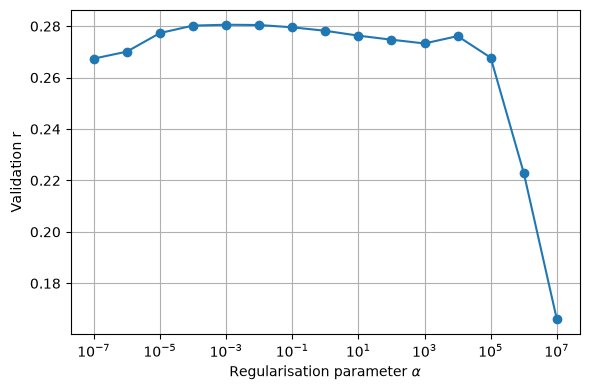

In [3]:
plt.figure(figsize=(6, 4))
plt.semilogx(alphas, [val_scores[a] for a in alphas], 'o-')
plt.xlabel(r'Regularisation parameter $\alpha$'); plt.ylabel('Validation r'); plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(FIG, "env_alpha.pdf"), bbox_inches="tight")
for a in alphas:
    print(f"{a:.0e}   {val_scores[a]:.4f}")

n_train = sum(eegs[i].shape[1] - n_lags + 1 for i in train)
print(f"training rows {n_train}   mean diag X'X {np.diag(XtX).mean():.3e}")
print(f"full lagged design {n_train * 63 * n_lags * 8 / 1e9:.2f} GB")

observed 0.2499   null mean 0.0007   null 95th 0.0341
p = 0.0010


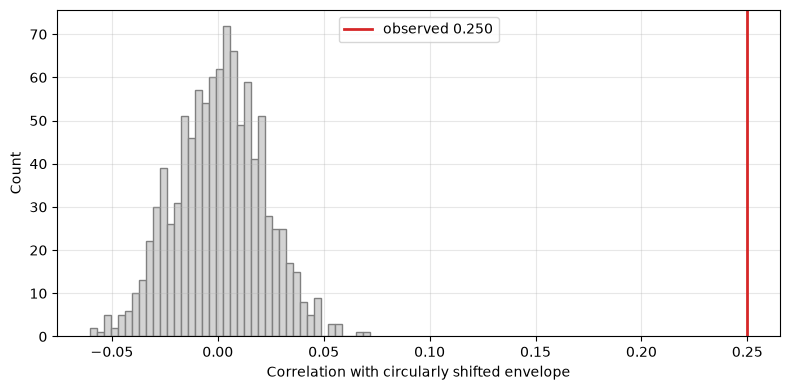

In [4]:
pred = np.hstack([lag_eeg(eegs[i], n_lags) @ ws[best] for i in test])
true_parts = [stims[i][:eegs[i].shape[1] - n_lags + 1] for i in test]
true = np.hstack(true_parts)

rng = np.random.default_rng(0)
def shift_each(parts):
    return np.hstack([np.roll(t, rng.integers(10*FS, len(t) - 10*FS)) for t in parts])

null = np.array([np.corrcoef(pred, shift_each(true_parts))[0, 1] for _ in range(1000)])

obs = np.corrcoef(pred, true)[0, 1]
print(f"observed {obs:.4f}   null mean {null.mean():.4f}   null 95th {np.percentile(null, 95):.4f}")
print(f"p = {((null >= obs).sum() + 1) / (len(null) + 1):.4f}")

plt.figure(figsize=(8, 4))
plt.hist(null, bins=40, color='lightgrey', edgecolor='grey')
plt.axvline(obs, c='tab:red', lw=2, label=f'observed {obs:.3f}')
plt.xlabel('Correlation with circularly shifted envelope'); plt.ylabel('Count')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(os.path.join(FIG, "env_null.pdf"), bbox_inches="tight")

part12  n 14549  r 0.3184
part13  n 13675  r 0.2250
part14  n 24573  r 0.2172


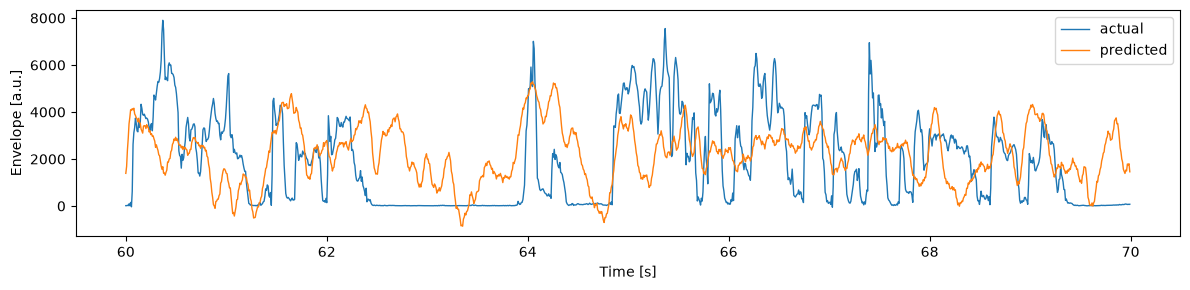

In [5]:
PRED = os.path.join(P05, "predictions")
os.makedirs(PRED, exist_ok=True)

for i in test:
    p = lag_eeg(eegs[i], n_lags) @ ws[best]
    s = np.load(os.path.join(P05, f"stim_part{i:02d}.npy"))
    r = np.corrcoef(p, stims[i][:len(p)])[0, 1]
    p = p / p.std() * s[:len(p)].std() + s[:len(p)].mean()
    np.save(os.path.join(PRED, f"pred_part{i:02d}.npy"), p)
    print(f"part{i:02d}  n {len(p)}  r {r:.4f}")

i = 12
p = np.load(os.path.join(PRED, f"pred_part{i:02d}.npy"))
s = np.load(os.path.join(P05, f"stim_part{i:02d}.npy"))[:len(p)]
t = np.arange(len(p)) / FS
seg = slice(60 * FS, 70 * FS)

plt.figure(figsize=(12, 3))
plt.plot(t[seg], s[seg], lw=1, label='actual')
plt.plot(t[seg], p[seg], lw=1, label='predicted')
plt.xlabel('Time [s]'); plt.ylabel('Envelope [a.u.]')
plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(FIG, "recon_time.pdf"), bbox_inches="tight")

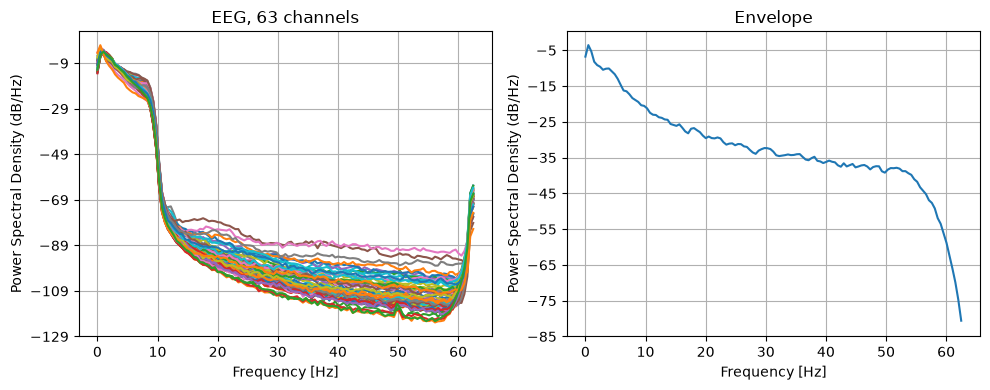

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
for i in range(63):
    axs[0].psd(eegs[1][i], Fs=FS)
axs[1].psd(stims[1], Fs=FS)
axs[0].set_title('EEG, 63 channels'); axs[1].set_title('Envelope')
for ax in axs: ax.set_xlabel('Frequency [Hz]')
plt.tight_layout()
plt.savefig(os.path.join(FIG, "env_psd.pdf"), bbox_inches="tight")

In [7]:
from scipy.signal import welch

hi, lo = [], []
for s in stims:
    f, P = welch(s, fs=FS, nperseg=1024)
    hi.append(P[f > 8].sum() / P.sum())
    lo.append(P[f < 0.5].sum() / P.sum())

print(f"envelope variance above 8 Hz:   mean {np.mean(hi)*100:.1f}%   "
      f"range {min(hi)*100:.1f} to {max(hi)*100:.1f}%")
print(f"envelope variance below 0.5 Hz: mean {np.mean(lo)*100:.1f}%   "
      f"range {min(lo)*100:.1f} to {max(lo)*100:.1f}%")

envelope variance above 8 Hz:   mean 6.8%   range 5.3 to 7.4%
envelope variance below 0.5 Hz: mean 29.3%   range 25.5 to 33.6%


In [8]:
def test_target(fn):
    return np.hstack([fn(stims[i])[:eegs[i].shape[1] - n_lags + 1] for i in test])

band = lambda s: filter_data(s.astype(float), FS, 0.5, 8, verbose=False)
low  = lambda s: s - filter_data(s.astype(float), FS, 0.5, None, verbose=False)
high = lambda s: s - filter_data(s.astype(float), FS, None, 8, verbose=False)

for name, fn in [("0.5-8 Hz", band), ("below 0.5 Hz", low), ("above 8 Hz", high)]:
    print(f"{name:<13} r with broadband reconstruction "
          f"{np.corrcoef(pred, test_target(fn))[0, 1]:.4f}")

0.5-8 Hz      r with broadband reconstruction 0.2447
below 0.5 Hz  r with broadband reconstruction 0.1175
above 8 Hz    r with broadband reconstruction 0.0010


In [9]:
r_broad = score(ws[best], test)       # broadband decoder, scored before the swap
stims_bp = [zscore(filter_data(s.astype(float), FS, 0.5, 8, verbose=False)) for s in stims]

stims_orig = stims
stims = stims_bp

XtX_bp, Xty_bp = accumulate(train)
ws_bp = {a: np.linalg.solve(XtX_bp + a * I, Xty_bp) for a in alphas}
best_bp = max(alphas, key=lambda a: score(ws_bp[a], val))

print(f"broadband    test r {r_broad:.4f}")
print(f"band-passed  alpha {best_bp:.1e}  test r {score(ws_bp[best_bp], test):.4f}")

stims = stims_orig

broadband    test r 0.2499
band-passed  alpha 1.0e-03  test r 0.2478
